pip install numpy  pandas  matplotlib  seaborn  plotly  scikit-learn 

In [1]:
import numpy as np # MATHEMETICAL COMPUTATIONS
import pandas as pd # DATA TRANSFORMATION 
import matplotlib.pyplot as plt # VISUAL
import seaborn as sns # VISUAL
import plotly.express as px # VISUAL
from sklearn.preprocessing import LabelEncoder , MinMaxScaler , StandardScaler # PREPROCESSING
from sklearn.model_selection import train_test_split 
from sklearn.linear_model  import LinearRegression # Model
from sklearn.metrics import mean_squared_error , mean_absolute_error

# 1) Data Aquisition

In [2]:
BS =pd.read_csv('boston.csv')

In [3]:
BS.head(1)

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,Price
0,0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.09,1,296,15.3,396.9,4.98,24.0


# 2) Cleaning & Preprocessing 

In [4]:
BS.columns

Index(['Unnamed: 0', 'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS',
       'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'Price'],
      dtype='object')

In [5]:
BS.drop('Unnamed: 0',axis=1,inplace=True)

In [6]:
BS.dtypes # MACHINE LEARNS ONLY NUMERIC RECORDS AND ALL COLUMNS ARE NUMERIC 
# HENCE NO TYPECASTING REQUIRED

CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX          int64
PTRATIO    float64
B          float64
LSTAT      float64
Price      float64
dtype: object

In [7]:
BS.isnull().sum() # No Missing Value

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
Price      0
dtype: int64

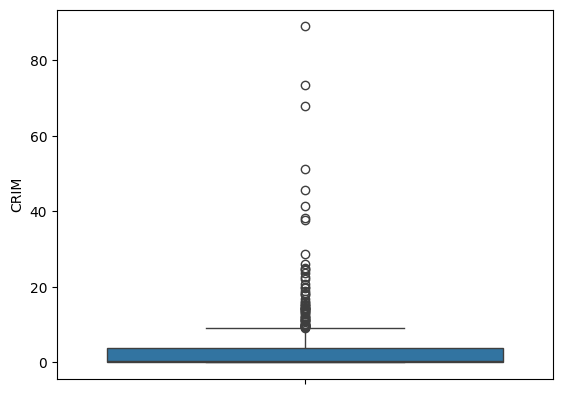

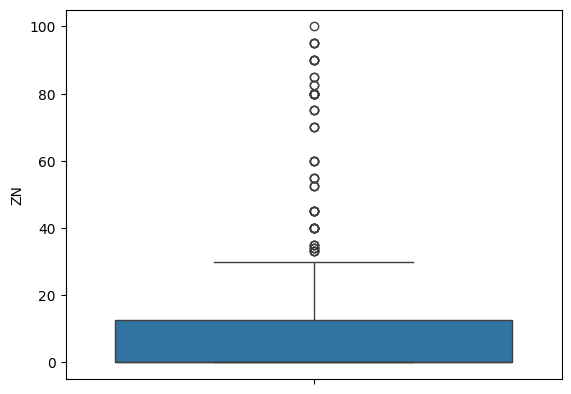

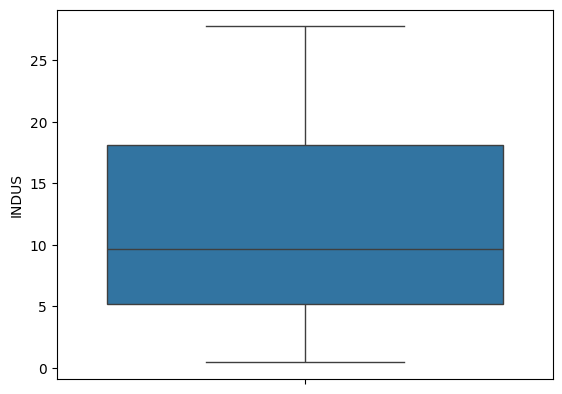

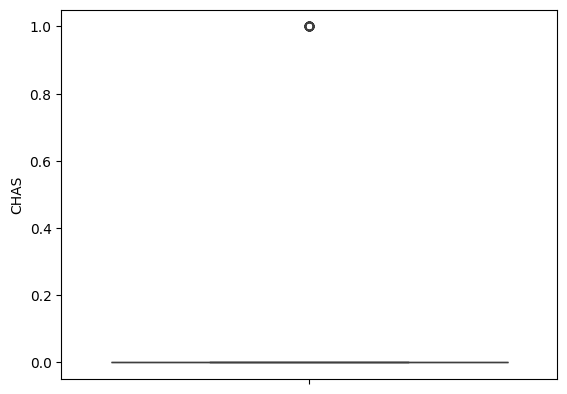

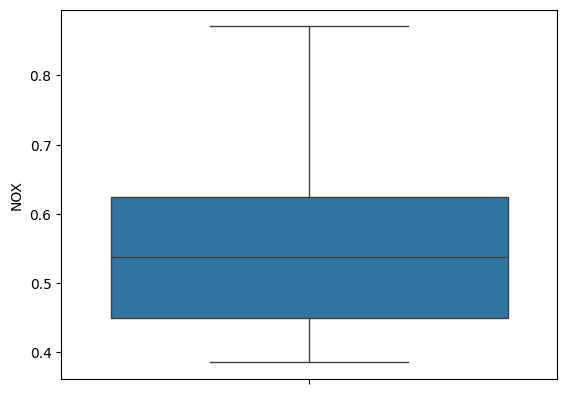

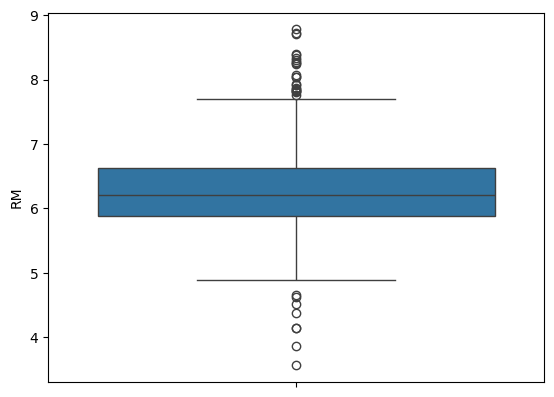

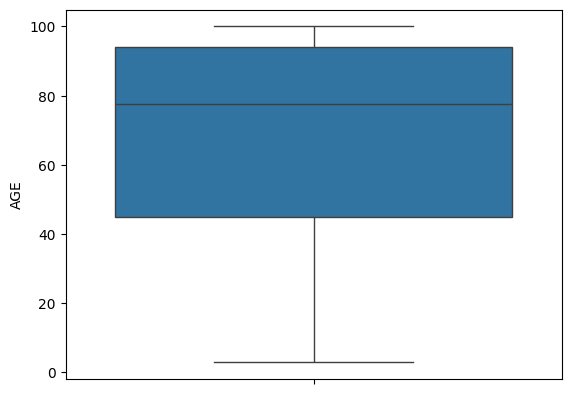

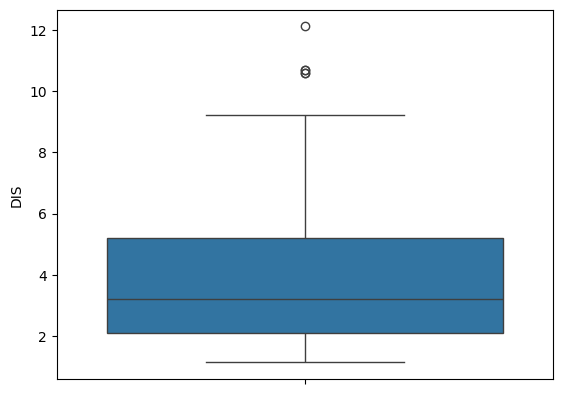

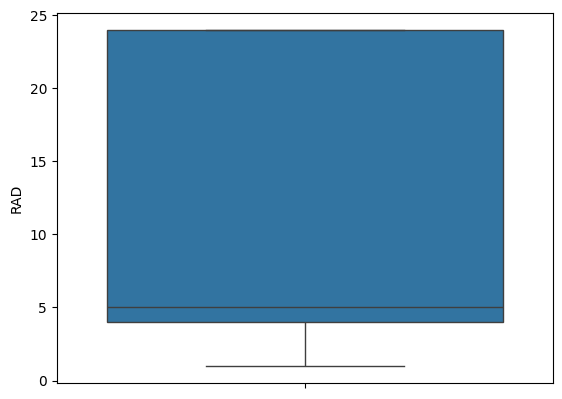

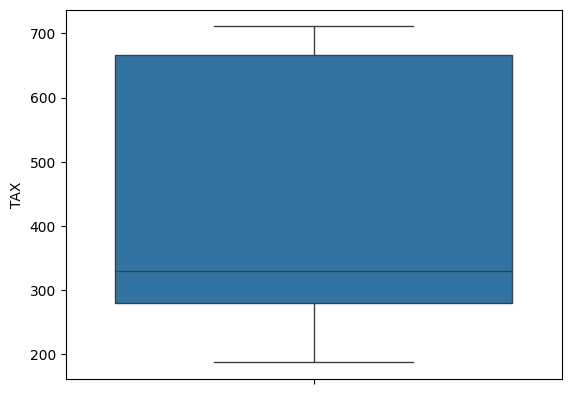

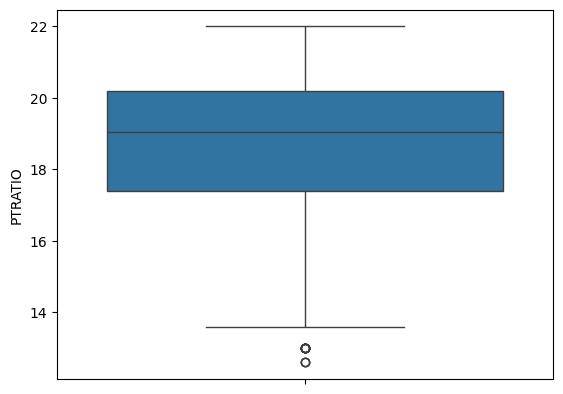

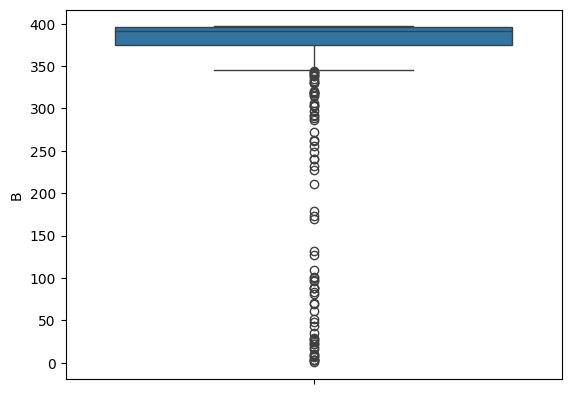

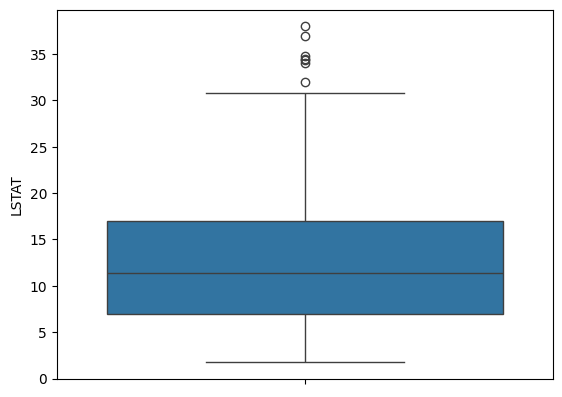

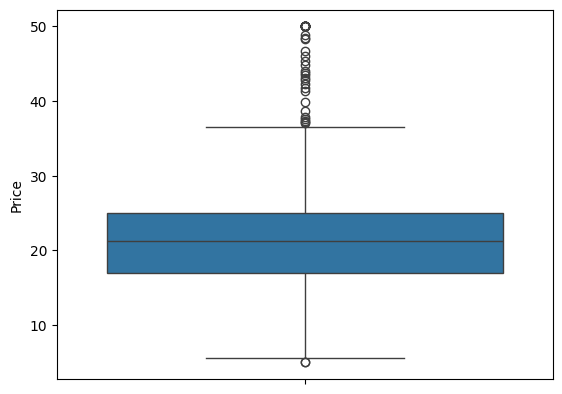

In [8]:
for col in BS.columns:
    sns.boxplot(BS[col])
    plt.show() # Data Contains outliers

# Zscore Method

In [9]:
Brows = BS.shape[0]

In [10]:
Brows

506

In [11]:
for col in BS.columns:
    STD3 = BS[col].std()*3
    Mean = BS[col].mean()
    Lower = Mean - STD3
    Upper = Mean + STD3
    Index = BS[col].between(Lower,Upper)
    BS = BS[Index]
    print(f'Column {col} Rows {BS.shape[0]}')

Column CRIM Rows 498
Column ZN Rows 484
Column INDUS Rows 484
Column CHAS Rows 450
Column NOX Rows 450
Column RM Rows 441
Column AGE Rows 441
Column DIS Rows 437
Column RAD Rows 437
Column TAX Rows 437
Column PTRATIO Rows 437
Column B Rows 414
Column LSTAT Rows 412
Column Price Rows 404


In [12]:
BS.shape

(404, 14)

In [13]:
STD3

23.77217448353075

In [14]:
Mean

22.258980582524273

In [15]:
Lower

-1.5131939010064777

In [16]:
Upper

46.03115506605502

In [17]:
(Index==False).sum()

8

In [18]:
Index

0      True
1      True
2      True
3      True
4      True
       ... 
501    True
502    True
503    True
504    True
505    True
Name: Price, Length: 412, dtype: bool

In [19]:
Arows = BS.shape[0]

In [20]:
Arows

404

In [21]:
print(f'Before outlier Removal {Brows} After outlier Removal {Arows}')

Before outlier Removal 506 After outlier Removal 404


In [22]:
404/506

0.7984189723320159

In [23]:
X = BS.drop('Price',axis=1) # independent data [on the basis of which we do predictions ]
Y = BS.Price # dependent data  [which we are predicting ]

In [24]:
MMS = MinMaxScaler()
X_Norm = MMS.fit_transform(X)

In [25]:
X_Norm = pd.DataFrame(data=X_Norm,columns=X.columns)

<Axes: >

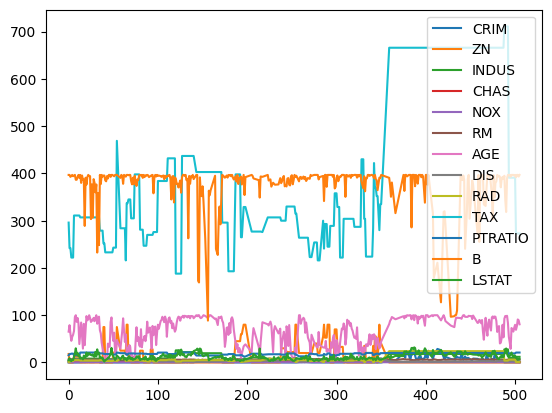

In [26]:
X.plot()

<Axes: >

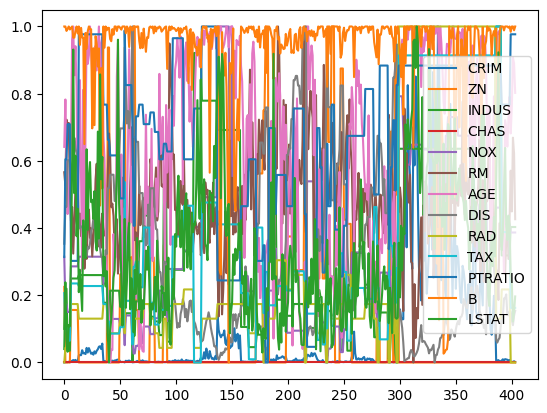

In [27]:
X_Norm.plot()

In [28]:
STD = StandardScaler()
X_STD = STD.fit_transform(X)

In [29]:
X_STD = pd.DataFrame(data=X_STD,columns=X.columns)

<Axes: >

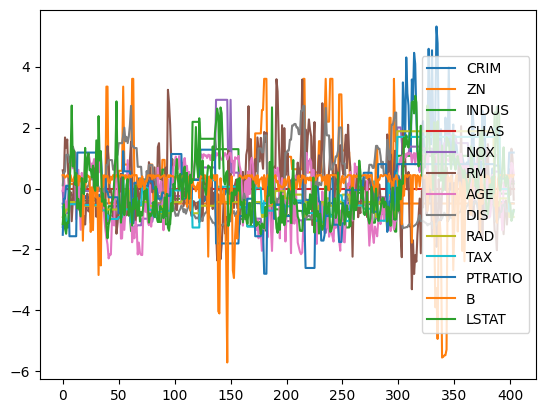

In [30]:
X_STD.plot()

X | X_Norm | X_STD

# 3) Train || [Develop]  Test || [Evaluation] Split

In [31]:
X_train , X_test , Y_train , Y_test = train_test_split(X , Y , test_size=0.25 , random_state = 42 ) 
# Normal state

In [32]:
NX_train , NX_test , NY_train , NY_test = train_test_split(X_Norm , Y , test_size=0.25 , random_state = 42 )
# Normalized Scaled

In [33]:
SX_train , SX_test , SY_train , SY_test = train_test_split(X_STD , Y , test_size=0.25 , random_state = 42 )
# Standardized Scaled

# 4) Model

In [34]:
LR = LinearRegression()

In [35]:
LR.fit(X_train , Y_train)

LinearRegression()

In [36]:
LR.coef_

array([-1.15769270e-01,  9.85095385e-03, -2.78353630e-02,  3.32373018e-14,
       -7.79787896e+00,  5.69690397e+00, -3.64197811e-02, -9.41677553e-01,
        1.49821438e-01, -1.11501459e-02, -7.91381739e-01,  6.16477556e-03,
       -2.48035112e-01])

In [37]:
LR.intercept_

15.507246974962849

# M1x1 + M2x2 + M3x3 ... + C 

In [38]:
LR.score(X_test , Y_test) # Linear model is able to reduce 76.6% error as compared with base model
# error is diference between actual vs prediction 
# Base model is when we do prediction on average [predict average of price column for all records]
# R_Square [R2_score]

0.7668855359907769

In [39]:
Pred = LR.predict(X_test)

In [40]:
Pred # predictions for X_test columns 

array([24.79457897, 32.13754415, 17.27283593, 14.62139021, 25.9297136 ,
       27.87341069, 14.39115599, 14.79947052, 15.2402293 , 18.35906887,
       16.43552184, 25.42731408, 22.79800846, 10.66970675, 24.68395596,
       33.67036637, 32.24750626, 16.60864   , 19.56865456, 22.92626327,
       21.79404467, 23.91362076, 32.74324001, 37.937726  , 20.02055914,
       23.65436465, 24.54322553, 21.87338769, 31.06349874, 18.84979079,
       15.67768296, 36.23172452, 28.6082088 , 18.90502227, 27.91439551,
       16.89879832, 20.18678245, 11.51973727, 27.27640857, 18.58561707,
       18.63421797,  5.43556561, 16.44885245, 19.67573493, 17.29716207,
       18.36877026, 13.90172373, 15.75896558, 29.93270769, 19.44590114,
       17.07663493, 17.20921544, 20.95383954, 21.36907378, 21.02966875,
       16.85898667, 21.819473  , 23.32088867, 29.0390993 , 26.65357437,
       17.16775132, 31.92824156, 13.2596332 , 21.36224421, 12.13046914,
       36.60213631, 21.30076894, 21.57439454, 17.59194478, 25.28

In [41]:
Y_test # actual for X_test columns 

73     23.4
259    30.1
486    19.1
33     13.1
42     25.3
       ... 
265    22.8
197    30.3
298    22.5
479    21.4
362    20.8
Name: Price, Length: 101, dtype: float64

In [42]:
(sum((Y_test-Pred)**2)/101)**0.5

3.2950139696132386

In [43]:
16**(1/2)

4.0

In [44]:
(sum(abs((Y_test-Pred)))/101)

2.5312594049102883

In [45]:
abs(-3345)

3345

In [46]:
len(X_test)

101

# Evaluation

In [47]:
print('MSE [Mean Squared Error] :' , mean_squared_error(Y_test , Pred )) # sigma((Y-Y^)^2)
print('MAE [Mean Absolute Error] :' , mean_absolute_error(Y_test , Pred )) # sigma(|Y-Y^|)
print('RMSE [Root Mean Squared Error] :' , mean_squared_error(Y_test , Pred )**0.5) # sqrt(sigma((Y-Y^)^2))
print('R Squred Value :' , LR.score(X_test , Y_test))

MSE [Mean Squared Error] : 10.857117059946393
MAE [Mean Absolute Error] : 2.531259404910289
RMSE [Root Mean Squared Error] : 3.2950139696132386
R Squred Value : 0.7668855359907769


In [48]:
LR = LinearRegression()
LR.fit(NX_train , NY_train)
NPred = LR.predict(NX_test)
print('MSE [Mean Squared Error] :' , mean_squared_error(Y_test , NPred ))
print('MAE [Mean Absolute Error] :' , mean_absolute_error(Y_test , NPred ))
print('RMSE [Root Mean Squared Error] :' , mean_squared_error(Y_test , NPred )**0.5)
print('R Squred Value :' , LR.score(NX_test , NY_test))

MSE [Mean Squared Error] : 10.857117059946356
MAE [Mean Absolute Error] : 2.5312594049102817
RMSE [Root Mean Squared Error] : 3.2950139696132332
R Squred Value : 0.7668855359907776


In [49]:
LR = LinearRegression()
LR.fit(SX_train , SY_train)
SPred = LR.predict(SX_test)
print('MSE [Mean Squared Error] :' , mean_squared_error(Y_test , SPred ))
print('MAE [Mean Absolute Error] :' , mean_absolute_error(Y_test , SPred ))
print('RMSE [Root Mean Squared Error] :' , mean_squared_error(Y_test , SPred )**0.5)
print('R Squred Value :' , LR.score(SX_test , Y_test))

MSE [Mean Squared Error] : 10.857117059946345
MAE [Mean Absolute Error] : 2.5312594049102803
RMSE [Root Mean Squared Error] : 3.2950139696132315
R Squred Value : 0.7668855359907779


In [50]:
pd.DataFrame({"Actual_Price":Y_test , "Predicted_Price" : Pred , "NormPrice" : NPred , "StdPrice" : SPred })

,Actual_Price,Predicted_Price,NormPrice,StdPrice
73,23.4,24.794579,24.794579,24.794579
259,30.1,32.137544,32.137544,32.137544
486,19.1,17.272836,17.272836,17.272836
33,13.1,14.621390,14.621390,14.621390
42,25.3,25.929714,25.929714,25.929714
...,...,...,...,...
265,22.8,25.321938,25.321938,25.321938
197,30.3,32.077974,32.077974,32.077974
298,22.5,27.133668,27.133668,27.133668
479,21.4,18.294948,18.294948,18.294948


# Adjusted R-squared = 1 − (1 − R²) × (n − 1) / (n − k − 1)

In [51]:
K = 1 # No. of variable
n = X.shape[0] #  No. of X rows
Adj_R2s = [] # empty list
for i in range(len(X.columns)):
    Rx = X.iloc[ :  ,  0:K]
    xtrain , xtest , ytrain , ytest =  train_test_split(Rx,Y,test_size=0.25,random_state=42)
    LR = LinearRegression()
    LR.fit(xtrain , ytrain) # will get coef and intercept to calculate prediction 
    R2 =  LR.score(xtest , ytest ) # findind R2 value 
    Adj_R2 = 1-(1-R2)*(n-1) / (n-K-1) # finding adjusted R2 Value 
    Adj_R2s.append(Adj_R2) # 
    K+=1

In [52]:
list(range(len(X.columns)))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

In [53]:
x_axis = list(range(1,len(Adj_R2s)+1))

In [54]:
y_axis = Adj_R2s

Text(0, 0.5, 'R2 value')

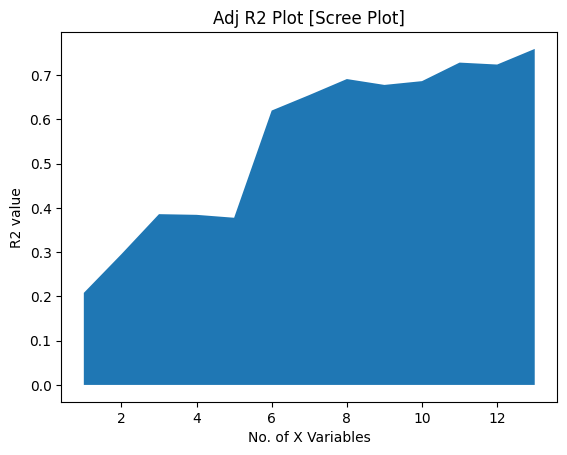

In [55]:
plt.fill_between(x_axis , y_axis)
plt.title('Adj R2 Plot [Scree Plot]')
plt.xlabel("No. of X Variables")
plt.ylabel("R2 value")

In [56]:
y_axis

[0.20793013633488888,
 0.2953462740165558,
 0.38580897075628295,
 0.38426964486845405,
 0.37767577121814067,
 0.6199007018821515,
 0.6548968456037658,
 0.6910496881146517,
 0.6777841291527628,
 0.6863341025208833,
 0.728208296478086,
 0.7238364215457818,
 0.7591150538571362]

In [57]:
DX = X.drop(['NOX','RAD'],axis=1)

In [58]:
xtrain , xtest , ytrain , ytest =  train_test_split(DX,Y,test_size=0.25,random_state=42)
LR = LinearRegression()
LR.fit(xtrain , ytrain) # will get coef and intercept to calculate prediction 
R2 =  LR.score(xtest , ytest ) # findind R2 value 


In [59]:
R2

0.7467218795820554

<Axes: >

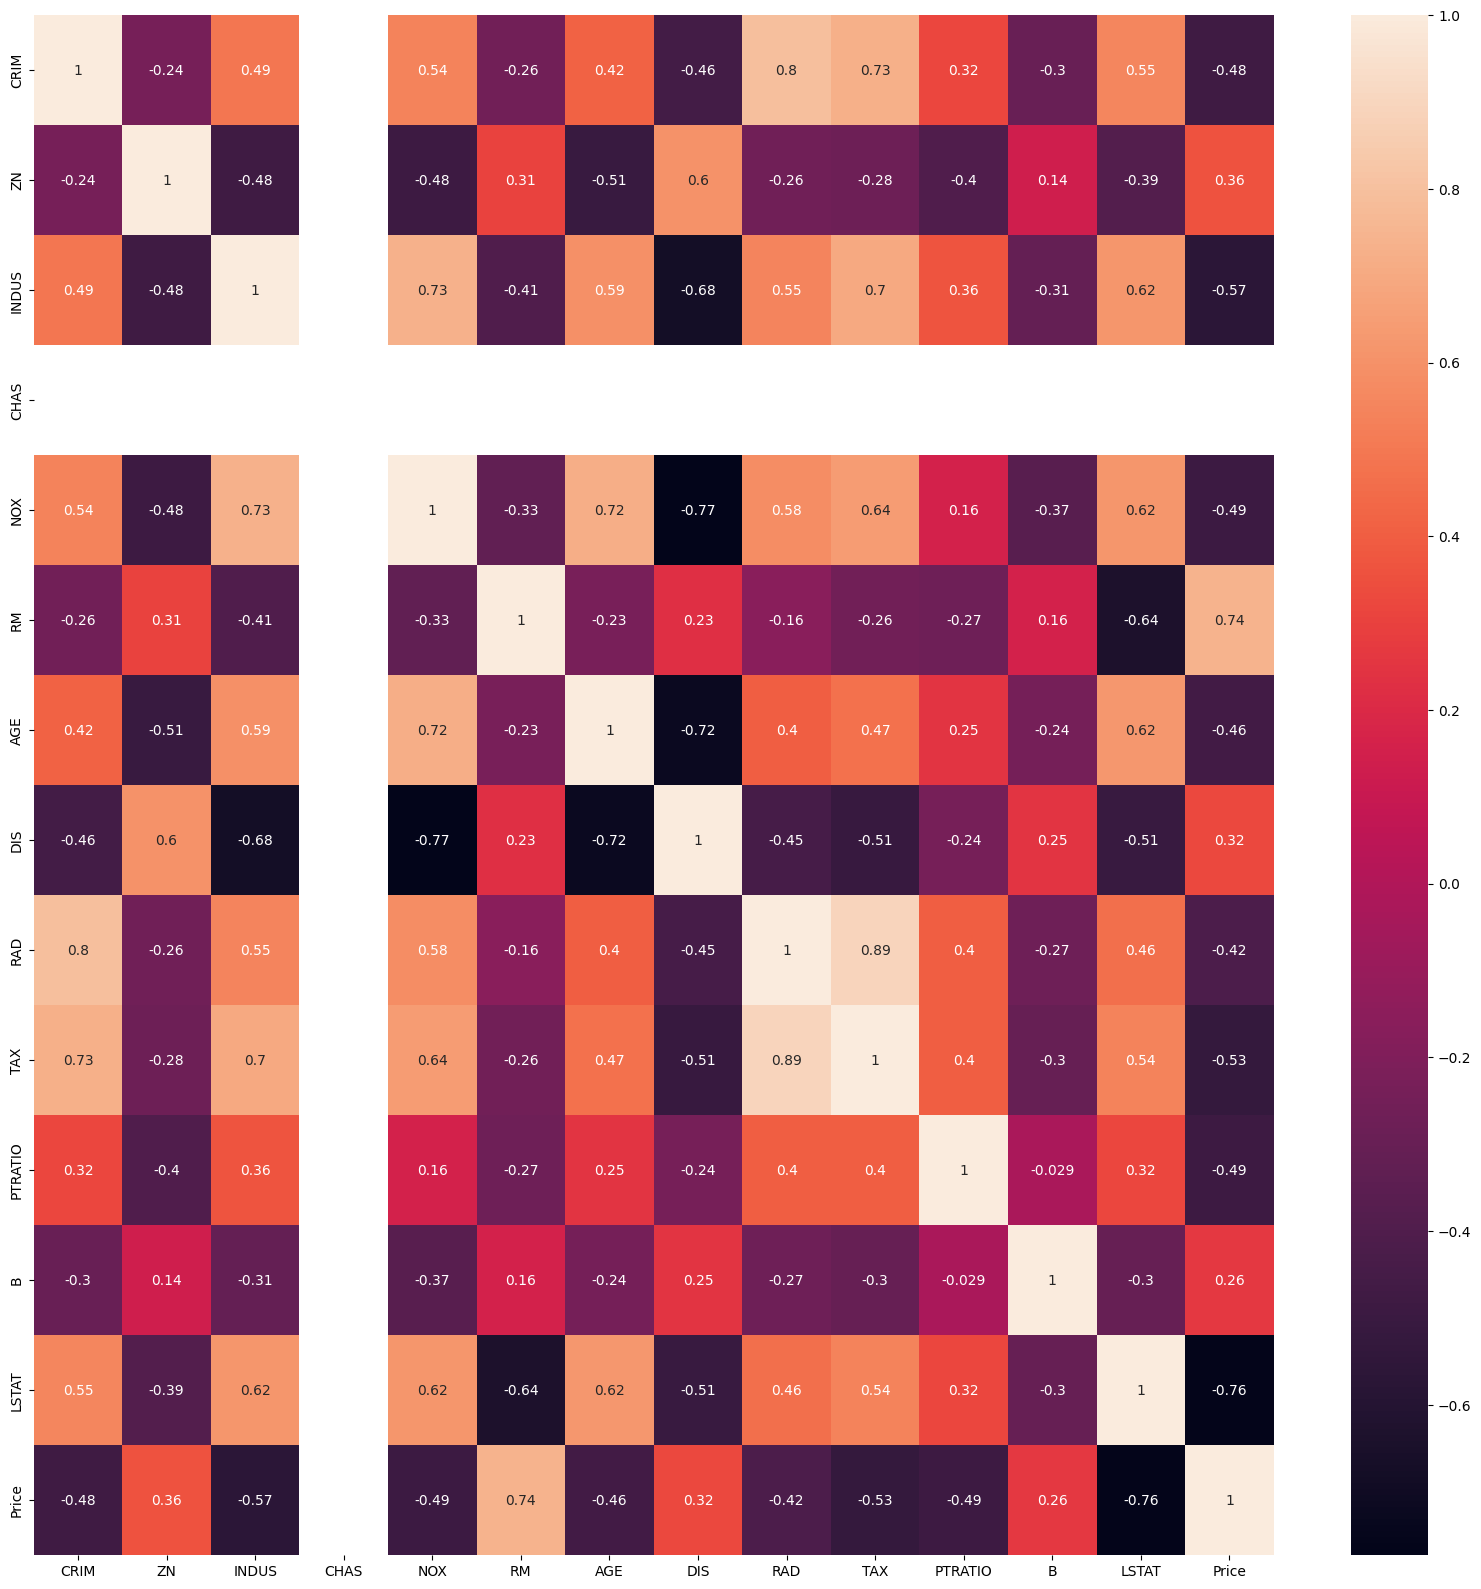

In [60]:
plt.figure(figsize=(20,20))
sns.heatmap(BS.corr(),annot=True)

In [61]:
DX = X[['RM','LSTAT','INDUS','TAX','PTRATIO','RAD','AGE','NOX','CRIM','ZN']]

In [62]:
xtrain , xtest , ytrain , ytest =  train_test_split(DX,Y,test_size=0.25,random_state=42)
LR = LinearRegression()
LR.fit(xtrain , ytrain) # will get coef and intercept to calculate prediction 
R2 =  LR.score(xtest , ytest ) # findind R2 value 

In [63]:
R2

0.7365605930022352

* optimizer [Regularization Techniques]
* optimize means we are trying to increase R2 value 
* Regularize means we ate trying to decrease the difference between R2 of Training and Testing 

# Regularization Techniques 

1) L1 [Ridge]
2) L2 [Lasso]
3) Elasticnet

In [64]:
from sklearn.linear_model import Ridge , Lasso , ElasticNet

In [65]:
L1 = Ridge()
L2 = Lasso()
EN = ElasticNet()

In [66]:
xtrain , xtest , ytrain , ytest =  train_test_split(X_STD,Y,test_size=0.25,random_state=42)

In [67]:
LR.fit(xtrain,ytrain)
print('L1 Training R2 Value : ',LR.score(xtrain,ytrain))
print('L1 Testing R2 Value :' , LR.score(xtest,ytest))

L1 Training R2 Value :  0.7955804224688562
L1 Testing R2 Value : 0.7668855359907779


In [68]:
L1.fit(xtrain,ytrain)
print('L1 Training R2 Value : ',L1.score(xtrain,ytrain))
print('L1 Testing R2 Value :' , L1.score(xtest,ytest))

L1 Training R2 Value :  0.7955624453200689
L1 Testing R2 Value : 0.7666339189615305


In [69]:
L2.fit(xtrain,ytrain)
print('L2 Training R2 Value : ',L2.score(xtrain,ytrain))
print('L2 Testing R2 Value :' , L2.score(xtest,ytest))

L2 Training R2 Value :  0.7278525245342684
L2 Testing R2 Value : 0.7278196651359963


In [70]:
EN.fit(xtrain,ytrain)
print('EN Training R2 Value : ',EN.score(xtrain,ytrain))
print('EN Testing R2 Value :' , EN.score(xtest,ytest))

EN Training R2 Value :  0.7086316671332052
EN Testing R2 Value : 0.712479541589877


# Ridge Lossfn(Y-Y^)^2 + /| * (slope)*2 

In [71]:
prop = 28 # actual price is Y
pred = 22 # prediction Y^

In [72]:
(28-22)**2 + (1* 50)**2

2536

In [73]:
LR.intercept_ # intercept C

21.656608119402822

In [74]:
LR.coef_ # Cofficient value 

array([-5.70518737e-01,  1.92584415e-01, -1.88539073e-01,  6.66133815e-16,
       -8.67614373e-01,  3.22142758e+00, -1.02236801e+00, -1.85532622e+00,
        1.22512441e+00, -1.79207416e+00, -1.67201992e+00,  3.09117652e-01,
       -1.59148628e+00])

Slope Mx+C

# Lasso 

In [75]:
(28-22)**2 + abs(1* 50)

86

1) Ridge = LossFn(LR )  + /| * (Slope)**2
2) Lasso = LossFn(LR )  + /| * |Slope|
3) Elastic = LossFn(LR) + Ridge + Lasso 

In [76]:
L1_pred = L1.predict(xtest)
L2_pred = L2.predict(xtest)
EN_pred = EN.predict(xtest)

In [77]:
actual = ytest

<Axes: xlabel='Price'>

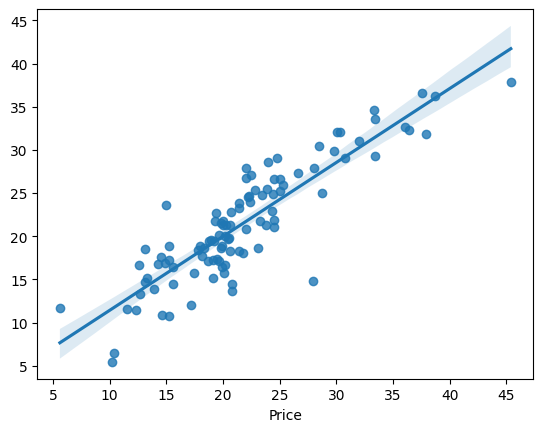

In [78]:
sns.regplot(x=actual,y=L1_pred)

<Axes: xlabel='Price'>

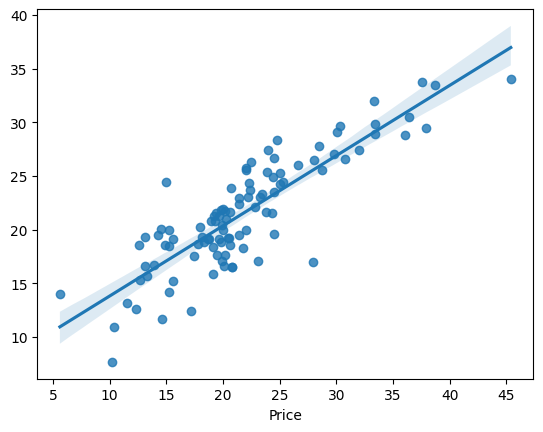

In [79]:
sns.regplot(x=actual,y=L2_pred)

<Axes: xlabel='Price'>

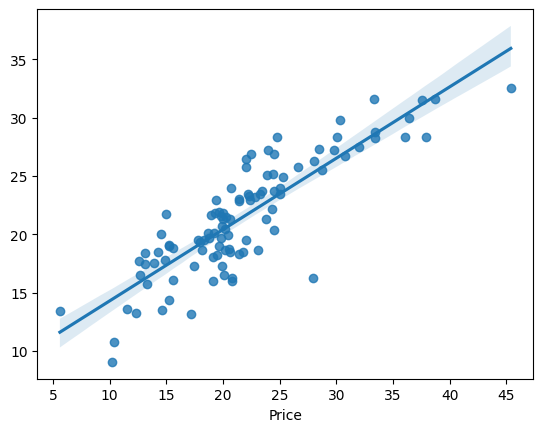

In [80]:
sns.regplot(x=actual,y=EN_pred)

In [81]:
sns.pairplot(BS)

Error in callback <function flush_figures at 0x000001CF7C7D1A80> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [89]:
BS['CHAS'].unique()

array([0], dtype=int64)

# Conclusion 

1) Data Aquisition [CSV File]
2) Data Cleaning and Preprocessing
   * Data Type [X data should have all numeric records]
   * Missing Data Treat [Data should not have any missing record]
   * outliers [Data should have any unexpected cases (Noise) ]
     
3) Train Test Split [Selection of records will be random ]
   * X independent data [by which we do prediction ]
   * Y dependent data [which we are predicting ]
   * Training Data is used to train Model
   * Testing Data is used to evaluate Model

4) Model Create using Linear Regression
    * Cofficient [M value]
    * Intercept [C value]
    * M1*x1 + M2*x2 + M3*x3 ... + C [formula for Prediction]

5) Performance Testing
   * MSE [Mean_Squared_Error]
   * MAE [Mean_Absolute_Error]
   * RMSE [Root_Mean_Squared Error]
   * R2 [R_Square Value]
   * Adj R2 [Adjusted R_Squared Value ]

6) Optimization and Regularization
   * optimize : Try to increase R2 value by selection of columns on the basis of correlation with Y

   * Regularization : Reduce the Difference between Train_R2 value and Testing_R2 value

   * Assumptions of Linear Regression
  
   * Overfitting : when model is performing good in Traning but Bad at the time of Testing
  
   * Underfitting : when model is performing bad in training and testing both
  

7) Deployment
   Making ur model Live on Website [Flask | Streamlit ]

8) Feedback and Monitoring    

# Interview Based Questions 

* Q1 what all are the types of linear regression ?
Ans : 
1) Simple Linear  Regression where we have single column in X data 
2) Multiple Linear Regression where we have more than 1 column in X data 

*Q2 what is the equation for simple linear Regression and Multiple Linear Regression ?
Ans :
1) Mx+c Simple Linear Regression 
2) M1x1 + M2x2 + M3x3 ... + C is for Multiple Linear Regression 

*Q3 What is the first step of cleaning and preprocessing of data for linear model  ?
Ans : Data Profilling [selection of correct data types]
      Machine understands numbers only so hence we will convert all categorical data into Numerical 

*Q4 Before Using Linear Regression what all are the points that we have to check ?
Ans : 
1) There should be a linear relationship between X and y 
2) Error Terms should be Normally Distributed [No outliers ]
3) There should be a Homoscedascisity in Data [all data points should be near to linear line ]
4) There should not be a problem of Multicolinearity [X1 is correlated with x2,x3,x4,x5...]
   * Correlation Threshold value is >0.6 and <-0.6
5) all columns of indepepndant data should act independently 


Q5 Step by Step Define Cleaning and Preprocssing of Data before entering in model ?
Ans :
1) Data Profilling 
   * all categorical data should be converted to Numeric   
2) Missing Value 
3) outliers 
4) correlation [Feature Engineering ]
5) Feature Scalling 


Q6 List the performance Metrics for Linear Regression ?
Ans: 
    1) MSE [Mean Squared Error]
    2) RMSE [Root Mean Squared Error]
    3) MAE [Mean Absolute Error]
    4) R2 [R Squared Value ]
    5) Adjusted R Squared Value 

Q7 What is the difference between Loss and Cost Function ?
Ans : 
    Loss function defines error of single prediction 
    whereas Cost function defines error of all predictions

Q8 what is the difference between overfitting and underfitting ?
Ans :
    Overfitting : when model is performing good at training but lapse at the time of testing 
    undefitting : when model is not performing good in both trianning and testing 
    Baseline is 0.6

In [90]:
 (lambda x: x * 2)(5)

10

In [91]:
 x = 5 if True else 10

In [92]:
x

5

In [93]:
'a' if 'a'>'b' else 'c'

'c'

In [94]:
(lambda x, y: x + y)(10, 20)

30

In [95]:
 type(x = 5 if True else 10)

TypeError: type() takes 1 or 3 arguments

In [96]:
print(bool([]))

False


In [97]:
import pickle

pickle.dump(LR, open("model.pkl", "wb"))
pickle.dump(list(X.columns), open("columns.pkl", "wb"))